# HW2 --- Data-Based (Surrogate) Modeling

Fill in the `# TODO` sections below to answer each question in `HW2.pdf`.
Dataset: [`aero_naca4_airfoil_panel.csv`](https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/Datasets/aero_naca4_airfoil_panel.csv)
(NACA 4-digit airfoil, vortex-panel method, $p=500$).

- **Inputs (6):** `max_camber_m`, `camber_pos_p`, `thickness_t`, `alpha_deg`, `mach`, `reynolds`
  (use $\log_{10}$(reynolds) in place of the raw column).
- **Output:** `CL`.
- **"Scaled inputs"** = per-column min--max scaling to $[0,1]$ using **training-set** bounds.

Starter code from Lecture 4's notebooks is linked in `HW2.pdf`; adapt it rather than
writing every model from a blank page. Each question below is copied verbatim from `HW2.pdf`;
Rename this file `<McGill_ID>_HW2.ipynb` before submitting.

## Setup: imports and data

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF as RBFKernel, ConstantKernel
from sklearn.model_selection import KFold
from scipy.interpolate import RBFInterpolator
from scipy.spatial.distance import cdist

RNG = 559  # fixed random seed -- pass it as random_state / default_rng(RNG) wherever a seed is needed

CSV_URL = "https://raw.githubusercontent.com/Ahmed-Bayoumy/MECH559/DEV/Datasets/aero_naca4_airfoil_panel.csv"
df = pd.read_csv(CSV_URL)
train = df[df.split == 'train'].reset_index(drop=True)
test = df[df.split == 'test'].reset_index(drop=True)
print(f"total={len(df)} train={len(train)} test={len(test)}")

raw_cols = ['max_camber_m', 'camber_pos_p', 'thickness_t', 'alpha_deg', 'mach']
feat_names = raw_cols + ['log10_reynolds']

def make_raw(d):
    """Return the 6 raw (unscaled) input columns, with reynolds -> log10(reynolds)."""
    X = d[raw_cols].to_numpy(dtype=float).copy()
    log10re = np.log10(d['reynolds'].to_numpy(dtype=float))
    return np.column_stack([X, log10re])

Xtr = make_raw(train); ytr = train['CL'].to_numpy(dtype=float)
Xte = make_raw(test);  yte = test['CL'].to_numpy(dtype=float)

def rmse(y, yhat):
    return float(np.sqrt(np.mean((y - yhat) ** 2)))

def r2(y, yhat):
    ss_res = np.sum((y - yhat) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return float(1 - ss_res / ss_tot)

# One set of 5 CV folds, created once and reused in Q3, Q4 and Q5, so every
# model and every hyperparameter value is scored on the same folds.
kf = KFold(n_splits=5, shuffle=True, random_state=RNG)

print("Xtr shape:", Xtr.shape, " Xte shape:", Xte.shape)

total=500 train=407 test=93
Xtr shape: (407, 6)  Xte shape: (93, 6)


## Question 1 --- Design of experiments

[`aero_naca4_airfoil_panel.csv`](https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/Datasets/aero_naca4_airfoil_panel.csv) was sampled with LHS ($n=6$, $p=500$), not a full-factorial grid. An LHS with $p$ points has $p$ distinct levels in every 1-D projection. Compute the full-factorial grid size needed to match this 1-D resolution ($p^{n}$ runs) and compare it to $p$; conversely, find how many levels per dimension a grid of at most $p$ runs can afford ($\lfloor p^{1/n}\rfloor$). Briefly explain why LHS avoids this *curse of dimensionality* while still space-filling well in 1-D.

In [2]:
n, p = 6, 500

grid_full = p ** n

levels_afford = int(np.floor(p ** (1 / n)))

print("Full grid:", grid_full, "runs")
print("LHS:", p, "runs")
print ("Afford:", levels_afford, "runs")
print("The full grid needs", grid_full // p, "times as many runs as LHS.")
print("Affordable levels per input:", levels_afford)
print ("LHS chooses one input variable per level, so it avoids redundency of multiple inputs in one interval and covers an entire range of input variables.", "\n", "So in our case we only need 2^6=64 runs to cover the entire range of input variables, without LHS the number of runs would increase a lot which is computationaly expensive.")

Full grid: 15625000000000000 runs
LHS: 500 runs
Afford: 2 runs
The full grid needs 31250000000000 times as many runs as LHS.
Affordable levels per input: 2
LHS chooses one input variable per level, so it avoids redundency of multiple inputs in one interval and covers an entire range of input variables. 
 So in our case we only need 2^6=64 runs to cover the entire range of input variables, without LHS the number of runs would increase a lot which is computationaly expensive.


## Question 2 --- Polynomial regression from first principles

Using the `train` rows, fit an affine model $\hat{y}(\mathbf{x};\mathbf{w}) = w_0 + \sum_{j=1}^{6} w_j x_j$ for `CL` (inputs: `max_camber_m`, `camber_pos_p`, `thickness_t`, `alpha_deg`, `mach`, $\log_{10}$(`reynolds`)) by solving the normal equations $\mathbf{Z}^{\mathsf T}\mathbf{Z}\,\mathbf{w} = \mathbf{Z}^{\mathsf T}\mathbf{y}$ directly -- adapt the Starter Code notebook's `normal_equations_fit`, or assemble $\mathbf{Z}$ yourself and pass $\mathbf{Z}^{\mathsf T}\mathbf{Z}$ and $\mathbf{Z}^{\mathsf T}\mathbf{y}$ to `numpy.linalg.solve` or MATLAB's backslash operator (no canned regression function; note that `lstsq`, or backslash applied to $\mathbf{Z}$ and $\mathbf{y}$ directly, does *not* form $\mathbf{Z}^{\mathsf T}\mathbf{Z}$). Report $\mathbf{w}$ and the test RMSE/$R^2$, then confirm both match `scikit-learn`'s `LinearRegression` (or MATLAB's `fitlm`).

In [3]:
# TODO: assemble the design matrix Z = [1 | Xtr] (intercept column + 6 raw inputs)
Ztr = np.column_stack([np.ones(len(Xtr)), Xtr])
Zte = np.column_stack([np.ones(len(Xte)), Xte])

# TODO: solve the normal equations directly -- do NOT call a regression library here
w = np.linalg.solve(Ztr.T @ Ztr, Ztr.T @ ytr)

# TODO: predict on the test set and report RMSE/R^2
yhat_te = Zte @ w
print("this is the RMSE and R^2 on the test set:")
print("RMSE:", rmse(yte, yhat_te), "\n", "R^2:", r2(yte, yhat_te))

# TODO: refit with scikit-learn's LinearRegression and confirm it matches
lr = LinearRegression().fit(Xtr, ytr)
yhat_library = lr.predict(Xte)

print("Library RMSE:", rmse(yte, yhat_library))
print("Library R²:", r2(yte, yhat_library))
print("yhat from library matches yhat from normal equations:", np.allclose(yhat_te, yhat_library))
print("The RMSE and R² from the library match the ones from the normal equations, confirming that our implementation is correct.")

w_library = np.concatenate(([lr.intercept_], lr.coef_))

print("Normal-equations coefficients:", w)
print("Library coefficients:", w_library)
print("Coefficients match:", np.allclose(w, w_library))

this is the RMSE and R^2 on the test set:
RMSE: 0.030767187788266273 
 R^2: 0.9952563688274003
Library RMSE: 0.030767187788266485
Library R²: 0.9952563688274003
yhat from library matches yhat from normal equations: True
The RMSE and R² from the library match the ones from the normal equations, confirming that our implementation is correct.
Normal-equations coefficients: [-2.93009248e-01  1.38489445e+01  3.46722606e-01  5.99521612e-01
  1.25720530e-01  1.76949369e-01  4.18197557e-03]
Library coefficients: [-2.93009248e-01  1.38489445e+01  3.46722606e-01  5.99521612e-01
  1.25720530e-01  1.76949369e-01  4.18197557e-03]
Coefficients match: True


## Question 3 --- Ill-conditioning and ridge regularization

Extend question 2 to a pure quadratic (add $w_{j+6}\,x_j^2$, 13 columns in $\mathbf{Z}$) and report $\kappa(\mathbf{Z}^{\mathsf T}\mathbf{Z})$. Min-max scale the inputs to $[0,1]$ (training-set bounds), rebuild $\mathbf{Z}$, and report the new condition number. Sweep the ridge penalty $\lambda \in \{0, 10^{-4}, 10^{-2}, 1, 100\}$ (adapt `ridge_fit`, i.e. $\mathbf{w}_{\text{ridge}} = (\mathbf{Z}^{\mathsf T}\mathbf{Z}+\lambda\mathbf{I})^{-1}\mathbf{Z}^{\mathsf T}\mathbf{y}$ on the scaled $\mathbf{Z}$; this penalizes $w_0$ too, so if you use `sklearn.linear_model.Ridge` pass your own column of ones with `fit_intercept=False` to get the same result); using 5-fold CV on the training set, plot CV RMSE vs. $\lambda$, report the best $\lambda$, and compare its test RMSE/$R^2$ to $\lambda=0$. **Relate this to the bias--variance trade-off and to $\kappa(\mathbf{Z}^{\mathsf T}\mathbf{Z}+\lambda\mathbf{I})$.**

Lambda = 0: CV RMSE = 0.03455655
Lambda = 0.0001: CV RMSE = 0.03455640
Lambda = 0.01: CV RMSE = 0.03455280
Lambda = 1: CV RMSE = 0.05484558
Lambda = 100: CV RMSE = 0.30701154
Best lambda: 0.01


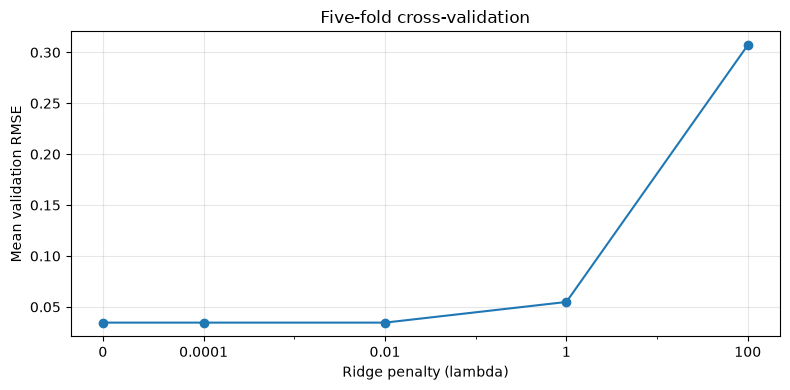

Best lambda: 0.01
Unscaled condition number: 26044113302.552944
Scaled condition number: 1496.4187946015716


,Model,Lambda,Test RMSE,Test R²,Condition number
0,No ridge,0.00,0.030816,0.995241,1496.418795
1,CV-selected ridge,0.01,0.030776,0.995254,1479.461864


In [4]:
# TODO: build the pure-quadratic design matrix (intercept + 6 linear + 6 squared terms, 13 cols)
def make_quad(Xraw): return np.column_stack([Xraw, Xraw**2])
Ztr_quad_raw = np.column_stack([np.ones(len(Xtr)), make_quad(Xtr)])

# TODO: report kappa(Z^T Z) on the UNSCALED quadratic features
np.linalg.cond(Ztr_quad_raw.T @ Ztr_quad_raw)

# TODO: min-max scale the 6 inputs to [0,1] using TRAINING bounds, then rebuild the quadratic Z
lo = Xtr.min(axis=0); hi = Xtr.max(axis=0)
def scale(X): return (X - lo) / (hi - lo)
Xtr_s, Xte_s = scale(Xtr), scale(Xte)

# TODO: report kappa(Z^T Z) on the SCALED quadratic features and compare to the unscaled value
Ztr_quad_s = np.column_stack([np.ones(len(Xtr_s)), make_quad(Xtr_s)])
Zte_quad_s = np.column_stack([np.ones(len(Xte_s)), make_quad(Xte_s)])

# TODO: sweep lambda in {0, 1e-4, 1e-2, 1, 100}; for each, run 5-fold CV on the training set
#       using the kf folds created in Setup (do NOT create new folds per lambda)
lambdas = [0, 1e-4, 1e-2, 1, 100]
cv_rmse = []

# Try each penalty value.
for lam in lambdas:
    fold_errors = []

    # Train and validate on each of the five folds.
    for tr_idx, va_idx in kf.split(Ztr_quad_s):
        Z_f = Ztr_quad_s[tr_idx]
        y_f = ytr[tr_idx]

        w_ridge = np.linalg.solve(
            Z_f.T @ Z_f + lam * np.eye(Z_f.shape[1]),
            Z_f.T @ y_f
        )

        yhat_validation = Ztr_quad_s[va_idx] @ w_ridge
        error = rmse(ytr[va_idx], yhat_validation)
        fold_errors.append(error)

    # Average the five validation errors.
    mean_error = np.mean(fold_errors)
    cv_rmse.append(mean_error)
    print(f"Lambda = {lam}: CV RMSE = {mean_error:.8f}")

best_lambda = lambdas[np.argmin(cv_rmse)]
print("Best lambda:", best_lambda)
# TODO: plot mean CV RMSE vs. lambda (semilogx), pick the best lambda

# TODO: fit on the full training set at lambda=0 and at the best lambda; compare test RMSE/R^2

# Plot validation error for each penalty.
plt.figure(figsize=(8, 4))
plt.plot(lambdas, cv_rmse, "o-")

# This scale allows lambda = 0 to appear.
plt.xscale("symlog", linthresh=1e-4)
plt.xticks(lambdas, ["0", "0.0001", "0.01", "1", "100"])

plt.xlabel("Ridge penalty (lambda)")
plt.ylabel("Mean validation RMSE")
plt.title("Five-fold cross-validation")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Best lambda:", best_lambda)

# Compare conditioning before and after scaling.
print(
    "Unscaled condition number:",
    np.linalg.cond(Ztr_quad_raw.T @ Ztr_quad_raw)
)
print(
    "Scaled condition number:",
    np.linalg.cond(Ztr_quad_s.T @ Ztr_quad_s)
)

# Fit on ALL training rows, then evaluate on the test rows.
results = []

for name, lam in [("No ridge", 0), ("CV-selected ridge", best_lambda)]:
    A = (
        Ztr_quad_s.T @ Ztr_quad_s
        + lam * np.eye(Ztr_quad_s.shape[1])
    )

    weights = np.linalg.solve(A, Ztr_quad_s.T @ ytr)
    predictions = Zte_quad_s @ weights

    results.append({
        "Model": name,
        "Lambda": lam,
        "Test RMSE": rmse(yte, predictions),
        "Test R²": r2(yte, predictions),
        "Condition number": np.linalg.cond(A)
    })

    # Keep the selected model for later questions.
    if name == "CV-selected ridge":
        w_best = weights
        yhat_best = predictions

display(pd.DataFrame(results))

## Question 4 --- RBF and its spread parameter

Fit a Gaussian RBF surrogate $\phi(r)=\exp(-\lambda r^2)$ for `CL` (same 6 scaled inputs) with the Starter Code notebook (replace its 1-D distance by the Euclidean distance in 6-D) or a library, sweeping the spread over $\geq4$ values across orders of magnitude (e.g. $\lambda\in[10^{-4},10^{3}]$; large $\lambda$ = narrow basis functions). If you use `scipy.interpolate.RBFInterpolator`, set `kernel='gaussian'` and `epsilon` $=\sqrt{\lambda}$ -- the default thin-plate kernel ignores `epsilon`; MATLAB's `newrbe` spread $s$ corresponds to $\lambda=(0.8326/s)^2$. Using 5-fold CV, plot CV RMSE vs. spread and identify the best value. **Relate the too-narrow/too-wide extremes to the "good spread" vs. "poor spread" behavior from lecture.**

Spread: 0.001 Mean validation RMSE: 0.010139996447827856
Spread: 0.01 Mean validation RMSE: 0.00031958282046698917


Spread: 0.1 Mean validation RMSE: 0.0004386375016560874
Spread: 1 Mean validation RMSE: 0.01130120322925324


Spread: 10 Mean validation RMSE: 0.22702589940345005
Spread: 100 Mean validation RMSE: 0.4857479863394619
Best spread: 0.01


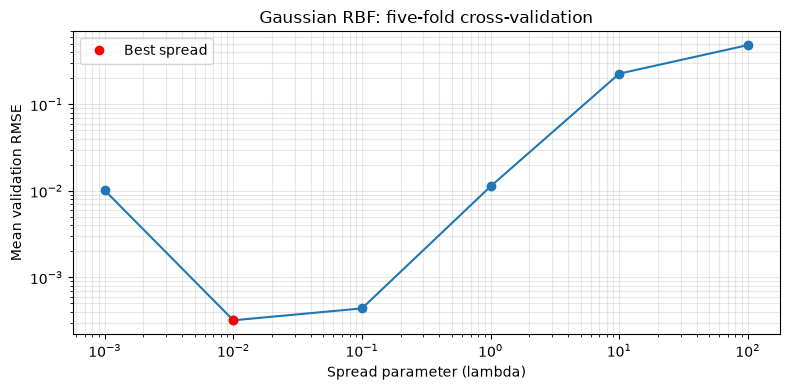

Test RMSE: 0.0002720400781952935
Test R²: 0.9999996291476018


In [5]:
# TODO: pick >= 4 spread values (lambda) spanning multiple orders of magnitude
spreads = [1e-3, 1e-2, 1e-1, 1, 10, 100]

# TODO: for each spread, run 5-fold CV (kf folds from Setup) using RBFInterpolator

rbf_cv_rmse = []

for lam in spreads:
    fold_errors = []

    for tr_idx, va_idx in kf.split(Xtr_s):
        # Training portion of this fold.
        Xtr_f = Xtr_s[tr_idx]
        ytr_f = ytr[tr_idx]

        # Validation portion of this fold.
        Xva_f = Xtr_s[va_idx]
        yva_f = ytr[va_idx]

        eps = np.sqrt(lam)
        rbfi = RBFInterpolator(
            Xtr_f, ytr_f,
            kernel="gaussian",
            epsilon=eps
        )

        fold_rmse = rmse(yva_f, rbfi(Xva_f))
        fold_errors.append(fold_rmse)

    mean_error = np.mean(fold_errors)
    rbf_cv_rmse.append(mean_error)
    print("Spread:", lam, "Mean validation RMSE:", mean_error)
# TODO: plot mean CV RMSE vs. spread (loglog), identify the best spread

# TODO: fit on the full (scaled) training set at the best spread; report test RMSE/R^2

# TODO: comment on the too-narrow vs. too-wide extremes of your sweep
# Choose the spread with the lowest mean validation error.
best_index = np.argmin(rbf_cv_rmse)
best_spread = spreads[best_index]

print("Best spread:", best_spread)

# Plot mean CV RMSE against spread.
plt.figure(figsize=(8, 4))
plt.loglog(spreads, rbf_cv_rmse, "o-")
plt.loglog(
    best_spread, rbf_cv_rmse[best_index],
    "ro", label="Best spread"
)
plt.xlabel("Spread parameter (lambda)")
plt.ylabel("Mean validation RMSE")
plt.title("Gaussian RBF: five-fold cross-validation")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Fit the selected model using ALL scaled training rows.
rbf_best = RBFInterpolator(
    Xtr_s, ytr,
    kernel="gaussian",
    epsilon=np.sqrt(best_spread)
)

# Predict lift for the test rows.
yhat_rbf = rbf_best(Xte_s)

print("Test RMSE:", rmse(yte, yhat_rbf))
print("Test R²:", r2(yte, yhat_rbf))

## Question 5 --- Neural network width as a complexity knob

Fit a single-hidden-layer network for `CL` (same 6 scaled inputs) with `MLPRegressor` (use `solver='lbfgs'`, `max_iter=5000`, a fixed `random_state`; the default `adam` with 200 iterations does not converge here) or `fitrnet`, sweeping the hidden-layer width over $\geq4$ values (e.g. 2, 8, 32, 64). Using 5-fold CV, plot CV RMSE vs. width and identify where under- and overfitting set in.

Width = 2: Training RMSE = 0.03391971, CV RMSE = 0.03493593
Width = 8: Training RMSE = 0.02582135, CV RMSE = 0.02811619


Width = 32: Training RMSE = 0.01602298, CV RMSE = 0.01775333
Width = 64: Training RMSE = 0.01038368, CV RMSE = 0.01287507
Best width: 64


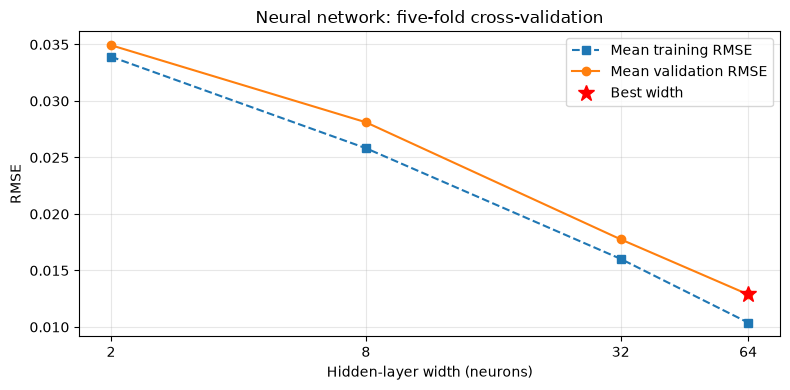

Test RMSE: 0.012169027831713931
Test R²: 0.9992579262339725


In [6]:
# TODO: pick >= 4 widths
widths = [2, 8, 32, 64]

# TODO: for each width, run 5-fold CV using MLPRegressor
nn_cv_rmse = []
nn_train_rmse = []

for width in widths:
    fold_errors = []
    fold_train_errors = []

    for tr_idx, va_idx in kf.split(Xtr_s):
        Xtr_f = Xtr_s[tr_idx]
        ytr_f = ytr[tr_idx]
        Xva_f = Xtr_s[va_idx]
        yva_f = ytr[va_idx]

        mlp = MLPRegressor(
            hidden_layer_sizes=(width,),
            solver="lbfgs",
            max_iter=5000,
            random_state=RNG,
            activation="relu",
            alpha=1e-4
        )

        mlp.fit(Xtr_f, ytr_f)

        fold_rmse = rmse(yva_f, mlp.predict(Xva_f))
        fold_errors.append(fold_rmse)
        fold_train_errors.append(rmse(ytr_f, mlp.predict(Xtr_f)))

    nn_cv_rmse.append(float(np.mean(fold_errors)))
    nn_train_rmse.append(float(np.mean(fold_train_errors)))

    print(
        f"Width = {width}: "
        f"Training RMSE = {nn_train_rmse[-1]:.8f}, "
        f"CV RMSE = {nn_cv_rmse[-1]:.8f}"
    )

best_width_index = int(np.argmin(nn_cv_rmse))
best_width = widths[best_width_index]
print("Best width:", best_width)

# TODO: plot mean CV RMSE vs. width (semilogx)
plt.figure(figsize=(8, 4))

plt.semilogx(
    widths, nn_train_rmse, "s--",
    label="Mean training RMSE"
)
plt.semilogx(
    widths, nn_cv_rmse, "o-",
    label="Mean validation RMSE"
)
plt.semilogx(
    best_width, nn_cv_rmse[best_width_index],
    "r*", markersize=12, label="Best width"
)

plt.xticks(widths, [str(width) for width in widths])
plt.minorticks_off()
plt.xlabel("Hidden-layer width (neurons)")
plt.ylabel("RMSE")
plt.title("Neural network: five-fold cross-validation")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# TODO: fit on the full training set at the best width;
#       report test RMSE/R²
mlp_best = MLPRegressor(
    hidden_layer_sizes=(best_width,),
    solver="lbfgs",
    max_iter=5000,
    random_state=RNG,
    activation="relu",
    alpha=1e-4
)

mlp_best.fit(Xtr_s, ytr)
yhat_nn = mlp_best.predict(Xte_s)

nn_test_rmse = rmse(yte, yhat_nn)
nn_test_r2 = r2(yte, yhat_nn)

print("Test RMSE:", nn_test_rmse)
print("Test R²:", nn_test_r2)

# TODO: comment on where the curve stops improving / starts overfitting


## Question 6 --- Kriging: correlation-matrix conditioning and uncertainty

Draw a fixed random subsample of $p=25$ training points (e.g. `np.random.default_rng(559)`) and use scaled inputs throughout this question. Using $R(\mathbf{x}_i,\mathbf{x}_j) = \exp(-\theta\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2)$ and the ordinary-Kriging equations from lecture ($\hat\beta = (\mathbf{1}^{\mathsf T}\mathbf{R}^{-1}\mathbf{1})^{-1}\mathbf{1}^{\mathsf T}\mathbf{R}^{-1}\mathbf{y}$, $\hat y(\mathbf{x}_{\text{new}}) = \hat\beta + \mathbf{r}^{\mathsf T}\mathbf{R}^{-1}(\mathbf{y}-\hat\beta\mathbf{1})$), adapt the Starter Code notebook's Kriging fit/predict (not a black-box library) for this sub-step. For $\geq3$ values of $\theta$ across orders of magnitude (e.g. $10^{-3}$ to $10^{2}$; call `kriging_fit` with `nugget=0`, since its default is $10^{-10}$), report $\kappa(\mathbf{R})$ and **comment on what a large value implies for computing $\mathbf{R}^{-1}$**; if $\mathbf{R}$ is (nearly) singular, apply a nugget $\mathbf{R}+\epsilon\mathbf{I}$ ($\epsilon\approx10^{-6}$) and show it helps. Then fit Kriging on the *full* training set with a GP library (e.g. `GaussianProcessRegressor` with `normalize_y=True` and an anisotropic `RBF(length_scale=np.ones(6))` kernel, or `fitrgp` with `'BasisFunction','constant'`); report test RMSE/$R^2$ and the predicted std at the test points nearest to and farthest from the training set, and comment on how the uncertainty relates to distance from the training data.

Theta = 0.001: condition number = 1.167809e+10
Theta = 0.01: condition number = 1.049578e+08
Theta = 0.1: condition number = 5.374277e+05
Theta = 1: condition number = 1.445966e+03
Theta = 10: condition number = 1.167939e+01
Theta = 100: condition number = 1.430026e+00

Worst-conditioned theta: 0.001
Condition number without nugget: 1.167809e+10
Condition number with nugget:    2.492245e+07
Reduction factor: 468.6

Subsample training RMSE without nugget: 1.5495061026186634e-06
Subsample training RMSE with nugget: 0.013624262020850758
The nugget improves numerical conditioning, but can sacrifice exact interpolation of the training values.


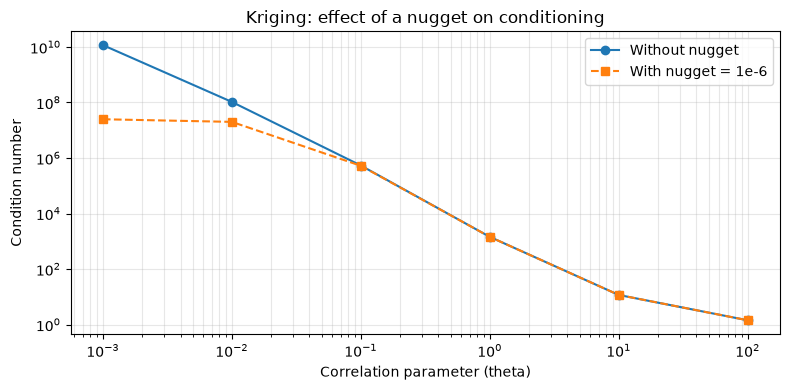


GP test RMSE: 0.00019965025759958907
GP test R^2: 0.9999998002553943

Nearest test point (zero-based index): 66
Distance to closest training point: 0.09993352143250597
Predicted standard deviation: 0.00015626802421256028

Farthest test point (zero-based index): 82
Distance to closest training point: 0.4452208374165805
Predicted standard deviation: 0.0004324048835656011


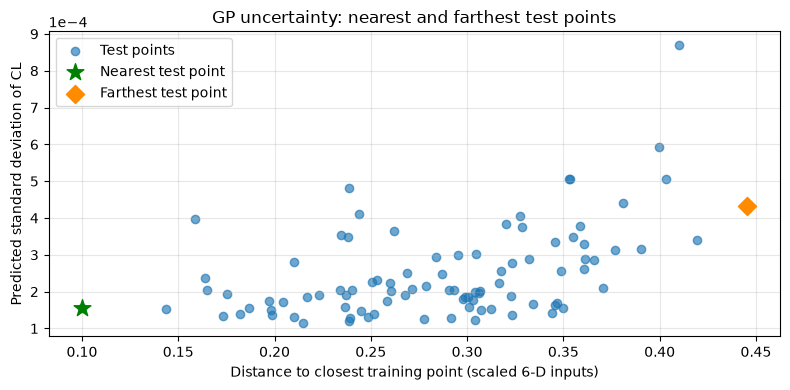

In [7]:


# TODO: implement the correlation matrix R(x_i, x_j) = exp(-theta * ||x_i - x_j||^2)
# hint: def corr_matrix(X1, X2, theta):
# d2 = ((X1[:, None, :] - X2[None, :, :]) ** 2).sum(-1)
# return np.exp(-theta * d2)

def corr_matrix(X1, X2, theta):
    d2 = ((X1[:, None, :] - X2[None, :, :]) ** 2).sum(-1)
    return np.exp(-theta * d2)


# TODO: implement kriging_fit(X, y, theta, nugget=0.0) -> model dict

def kriging_fit(X, y, theta, nugget=0.0):
    R = corr_matrix(X, X, theta) + nugget * np.eye(len(X))
    Rinv = np.linalg.inv(R)
    ones = np.ones(len(X))

    beta = (ones.T @ Rinv @ y) / (ones.T @ Rinv @ ones)

    return {
        "X": X,
        "y": y,
        "theta": theta,
        "R": R,
        "Rinv": Rinv,
        "beta": beta
    }


# TODO: implement kriging_predict(Xnew, model) -> yhat


def kriging_predict(Xnew, model):
    X = model["X"]
    y = model["y"]
    theta = model["theta"]
    Rinv = model["Rinv"]
    beta = model["beta"]

    r = corr_matrix(Xnew, X, theta)
    yhat = beta + r @ Rinv @ (y - beta)
    return yhat


# TODO: draw p=25 training points with a fixed seed

rng = np.random.default_rng(RNG)
sub_idx = rng.choice(len(Xtr_s), size=25, replace=False)

Xsub = Xtr_s[sub_idx]
ysub = ytr[sub_idx]


# TODO: for >= 3 theta values spanning orders of magnitude, report kappa(R) (nugget=0)
# hint: np.linalg.cond(corr_matrix(Xsub, Xsub, theta))

thetas = [1e-3, 1e-2, 1e-1, 1, 10, 100]
condition_numbers = []

for theta in thetas:
    kappa = np.linalg.cond(corr_matrix(Xsub, Xsub, theta))
    condition_numbers.append(kappa)

    print(f"Theta = {theta:g}: condition number = {kappa:.6e}")


# TODO: for the worst-conditioned theta, show that a nugget (R + 1e-6*I) helps

worst_theta = thetas[int(np.argmax(condition_numbers))]

model_no_nugget = kriging_fit(Xsub, ysub, worst_theta, nugget=0.0)
model_with_nugget = kriging_fit(Xsub, ysub, worst_theta, nugget=1e-6)

cond_before = np.linalg.cond(model_no_nugget["R"])
cond_after = np.linalg.cond(model_with_nugget["R"])

print("\nWorst-conditioned theta:", worst_theta)
print(f"Condition number without nugget: {cond_before:.6e}")
print(f"Condition number with nugget:    {cond_after:.6e}")
print(f"Reduction factor: {cond_before / cond_after:.1f}")

# Demonstrate our predictor at the 25 training points.
yhat_sub_no_nugget = kriging_predict(Xsub, model_no_nugget)
yhat_sub_with_nugget = kriging_predict(Xsub, model_with_nugget)

print("\nSubsample training RMSE without nugget:",
      rmse(ysub, yhat_sub_no_nugget))
print("Subsample training RMSE with nugget:",
      rmse(ysub, yhat_sub_with_nugget))

print(
    "The nugget improves numerical conditioning, "
    "but can sacrifice exact interpolation of the training values."
)

# Plot conditioning with and without a nugget for the same theta values.
condition_numbers_nugget = []

for theta in thetas:
    R_nugget = corr_matrix(Xsub, Xsub, theta) + 1e-6 * np.eye(len(Xsub))
    condition_numbers_nugget.append(np.linalg.cond(R_nugget))

plt.figure(figsize=(8, 4))
plt.loglog(thetas, condition_numbers, "o-", label="Without nugget")
plt.loglog(
    thetas, condition_numbers_nugget, "s--",
    label="With nugget = 1e-6"
)
plt.xlabel("Correlation parameter (theta)")
plt.ylabel("Condition number")
plt.title("Kriging: effect of a nugget on conditioning")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

from scipy.optimize import minimize
from threadpoolctl import threadpool_limits


def gp_optimizer(obj_func, initial_theta, bounds):
    result = minimize(
        obj_func,
        initial_theta,
        method="L-BFGS-B",
        jac=True,
        bounds=bounds,
        options={
            "maxiter": 2000,
            "maxls": 100,
            "ftol": 1e-7
        }
    )

    if not result.success:
        raise RuntimeError(f"GP optimization failed: {result.message}")

    return result.x, result.fun


# --- Part B: full-scale fit with a GP library ---------------------------------------

# TODO: fit GaussianProcessRegressor on the FULL scaled training set
# hint: kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBFKernel(length_scale=np.ones(6),
# length_scale_bounds=(1e-2, 1e3))
# hint: gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True,
# n_restarts_optimizer=3, random_state=RNG)
# hint: yhat_gp, std_gp = gp.predict(Xte_s, return_std=True)

kernel = ConstantKernel(1.0, (1e-3, 1e4)) * RBFKernel(
    length_scale=np.ones(6),
    length_scale_bounds=(1e-2, 1e8)
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-6,
    optimizer=gp_optimizer,
    normalize_y=True,
    n_restarts_optimizer=3,
    random_state=RNG
)

with threadpool_limits(limits=1):
    gp.fit(Xtr_s, ytr)
    yhat_gp, std_gp = gp.predict(Xte_s, return_std=True)

# Report test RMSE and R^2.
print("\nGP test RMSE:", rmse(yte, yhat_gp))
print("GP test R^2:", r2(yte, yhat_gp))

# Find the nearest and farthest test points in scaled 6-D space.
D = cdist(Xte_s, Xtr_s)
min_dist = D.min(axis=1)
i_near, i_far = np.argmin(min_dist), np.argmax(min_dist)

# Report each point's distance and predicted standard deviation.
print("\nNearest test point (zero-based index):", i_near)
print("Distance to closest training point:", min_dist[i_near])
print("Predicted standard deviation:", std_gp[i_near])

print("\nFarthest test point (zero-based index):", i_far)
print("Distance to closest training point:", min_dist[i_far])
print("Predicted standard deviation:", std_gp[i_far])

# Plot GP uncertainty and highlight the nearest and farthest test points.
plt.figure(figsize=(8, 4))
plt.scatter(min_dist, std_gp, alpha=0.65, label="Test points")
plt.scatter(
    min_dist[i_near], std_gp[i_near],
    marker="*", s=160, color="green", zorder=3,
    label="Nearest test point"
)
plt.scatter(
    min_dist[i_far], std_gp[i_far],
    marker="D", s=85, color="darkorange", zorder=3,
    label="Farthest test point"
)
plt.xlabel("Distance to closest training point (scaled 6-D inputs)")
plt.ylabel("Predicted standard deviation of CL")
plt.title("GP uncertainty: nearest and farthest test points")
plt.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Bonus (optional, no penalty for skipping) --- Comparing surrogate families

Collect your tuned models (CV-selected; Kriging by maximum likelihood) from questions 3--6 -- quadratic+ridge, RBF, ANN, Kriging -- into one table of test RMSE/$R^2$ for `CL`, each family's complexity knob, and whether it gives native uncertainty quantification (mirroring lecture's "Family / Complexity knob / Native UQ?" comparison). State which family you'd recommend and why, citing a property from the table.

In [8]:
# TODO: build a summary table with one row per family
# hint: rows = [("Polynomial (quad+ridge)", f"lambda=...", rmse_..., r2_..., "No"),
#               ("RBF",                     f"spread=...", rmse_..., r2_..., "No"),
#               ("ANN",                     f"width=...",  rmse_..., r2_..., "No"),
#               ("Kriging/GP",              "theta (MLE)", rmse_..., r2_..., "Yes (std)")]
# hint: pd.DataFrame(rows, columns=["Family","Knob","Test RMSE","Test R2","Native UQ"])

# Use the selected models and test predictions from Questions 3--6.
rows = [
    ("Polynomial (quad+ridge)", f"lambda={best_lambda:g}",
     rmse(yte, yhat_best), r2(yte, yhat_best), "No"),
    ("RBF", f"spread={best_spread:g}",
     rmse(yte, yhat_rbf), r2(yte, yhat_rbf), "No"),
    ("ANN", f"width={best_width}",
     rmse(yte, yhat_nn), r2(yte, yhat_nn), "No"),
    ("Kriging/GP", "theta (MLE)",
     rmse(yte, yhat_gp), r2(yte, yhat_gp), "Yes (std)")
]

bonus_table = pd.DataFrame(
    rows, columns=["Family", "Knob", "Test RMSE", "Test R2", "Native UQ"]
)

with pd.option_context("display.precision", 10):
    display(bonus_table)

# TODO: state which family you'd recommend and why (in the Answer cell below)

,Family,Knob,Test RMSE,Test R2,Native UQ
0,Polynomial (quad+ridge),lambda=0.01,0.0307755112,0.9952538019,No
1,RBF,spread=0.01,0.0002720401,0.9999996291,No
2,ANN,width=64,0.0121690278,0.9992579262,No
3,Kriging/GP,theta (MLE),0.0001996503,0.9999998003,Yes (std)
